In [1]:
# =========================================================
# IMPORTS
# =========================================================
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification, make_moons
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import accuracy_score, precision_score

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC


In [2]:
'''
  1. Generowanie danych
  Użyj biblioteki scikit-learn.
  Wygeneruj zbiór danych funkcją make_moons(n_samples=10000, noise=0.25).
  Podziel dane na zbiór uczący i testowy metodą train_test_split().
'''
# =========================================================
# DATA GENERATION
# =========================================================

# Nonlinear dataset
X_nonlin, y_nonlin = make_moons(
    n_samples=10000,
    noise=0.25,
    # random_state=42
)

# Train/test split (use nonlinear dataset for main experiments)
X_train, X_test, y_train, y_test = train_test_split(
    X_nonlin, y_nonlin, test_size=0.3, random_state=42
)

In [3]:
# =========================================================
# VISUALIZATION FUNCTION WITH METRICS
# =========================================================
def plot_decision_boundary_with_metrics(
    model,
    X_train,
    y_train,
    X_test,
    y_test,
    title="Model",
    show_precision=False
):
    """
    Plot decision boundary + metrics.

    Displays:
    - Train accuracy
    - Test accuracy
    - Optional precision
    """

    h = 0.02

    # Define grid
    x_min = min(X_train[:, 0].min(), X_test[:, 0].min()) - 1
    x_max = max(X_train[:, 0].max(), X_test[:, 0].max()) + 1
    y_min = min(X_train[:, 1].min(), X_test[:, 1].min()) - 1
    y_max = max(X_train[:, 1].max(), X_test[:, 1].max()) + 1

    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, h),
        np.arange(y_min, y_max, h)
    )

    # Predict grid
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Predictions on real data
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Metrics
    train_acc = accuracy_score(y_train, y_train_pred)
    test_acc = accuracy_score(y_test, y_test_pred)

    if show_precision:
        precision = precision_score(y_test, y_test_pred)
        metrics_text = f"Train={train_acc:.2f} | Test={test_acc:.2f} | Prec={precision:.2f}"
    else:
        metrics_text = f"Train={train_acc:.2f} | Test={test_acc:.2f}"

    # Plot
    plt.contourf(xx, yy, Z, alpha=0.3)
    plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, marker='o', label="Train")
    plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, marker='x', label="Test")

    plt.title(f"{title}\n{metrics_text}")
    plt.legend()
    plt.show()

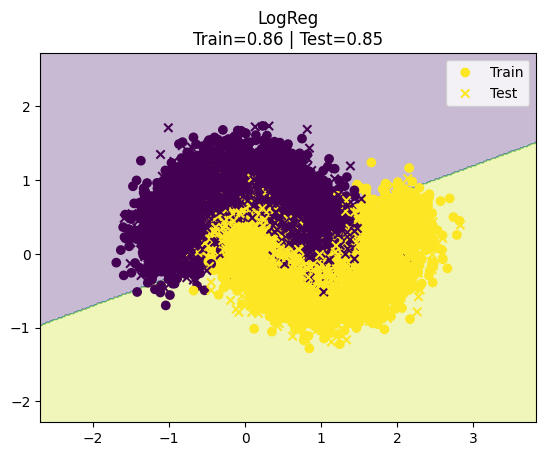

In [4]:
'''
  2. Regresja logistyczna
  Zaimplementuj model w pliku reglog.py i wytrenuj klasyfikator.
  Napisz metodę zwracającą prawdopodobieństwa przynależności do klas.
  Nie używaj gotowych implementacji perceptronu ani regresji logistycznej z bibliotek.
'''

import numpy as np  # Import NumPy for numerical operations (arrays, vectors, matrices)
import matplotlib.pyplot as plt  # Import Matplotlib for plotting


class LogisticRegression:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        """
        Logistic Regression Classifier (Student Template)

        This class implements binary classification using logistic regression
        trained with gradient descent.

        Parameters:
        - learning_rate: Step size for gradient updates
        - n_iterations: Number of training iterations (epochs)
        """
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

    def train(self, X, y):
        """
        Train the logistic regression model.

        Parameters:
        - X: Feature matrix (n_samples, n_features)
        - y: Binary labels (0 or 1)
        """
        n_samples, n_features = X.shape

        self.weights = np.zeros(n_features)  # Initialize weights
        self.bias = 0  # Initialize bias

        for _ in range(self.n_iterations):
            linear_model = np.dot(X, self.weights) + self.bias  # Linear combination
            y_predicted = self.sigmoid(linear_model)  # Apply sigmoid function

            # Compute gradients
            dw = (1 / n_samples) * np.dot(X.T, (y_predicted - y))
            db = (1 / n_samples) * np.sum(y_predicted - y)

            # Update parameters
            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db

    def predict(self, X):
        """
        Predict binary class labels.

        Parameters:
        - X: Input data

        Returns:
        - Predicted labels (0 or 1) as a NumPy array
        """
        linear_model = np.dot(X, self.weights) + self.bias
        y_predicted = self.sigmoid(linear_model)

        # Convert probabilities to class labels using threshold 0.5 and return as NumPy array
        y_predicted_cls = (y_predicted > 0.5).astype(int)
        return y_predicted_cls

    def predict_probability(self, X):
        """
        Predict class probabilities.

        Parameters:
        - X: Input data

        Returns:
        - Probabilities in range [0, 1]
        """
        linear_model = np.dot(X, self.weights) + self.bias
        y_predicted = self.sigmoid(linear_model)
        return y_predicted

    def sigmoid(self, x):
        """
        Sigmoid activation function.

        Uses clipping to prevent numerical overflow.
        """
        return 1 / (1 + np.exp(-np.clip(x, -250, 250)))

    def accuracy(self, X, y):
        """
        Compute classification accuracy.

        Parameters:
        - X: Input data
        - y: True labels

        Returns:
        - Accuracy (fraction of correct predictions)
        """
        predictions = self.predict(X)
        correct = np.sum(predictions == y)
        total = len(y)
        return correct / total



# Train model
n_iterations = 10000
logisticregression = LogisticRegression(n_iterations=n_iterations)
logisticregression.train(X_train, y_train)

plot_decision_boundary_with_metrics(
    logisticregression,
    X_train, y_train,
    X_test, y_test,
    title=f"LogReg"
)



=== Decision Tree ===


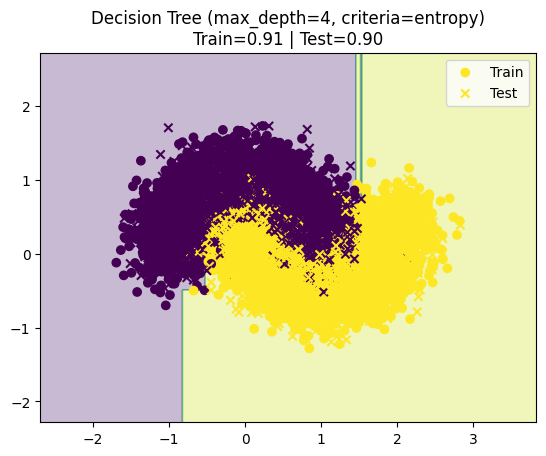

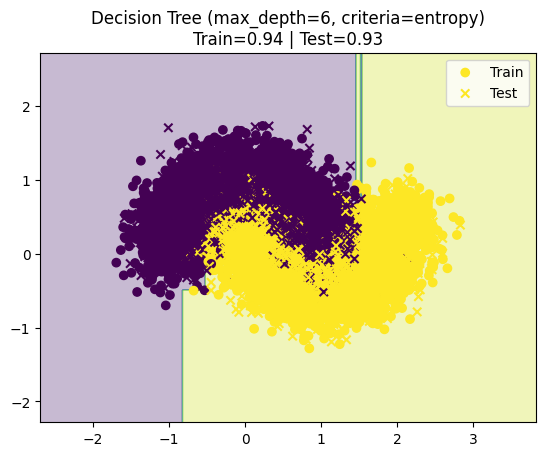

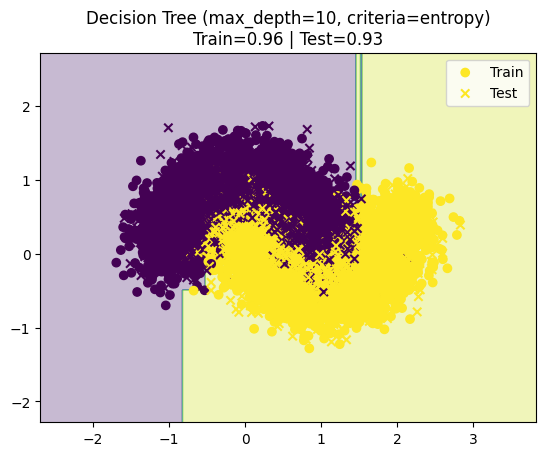

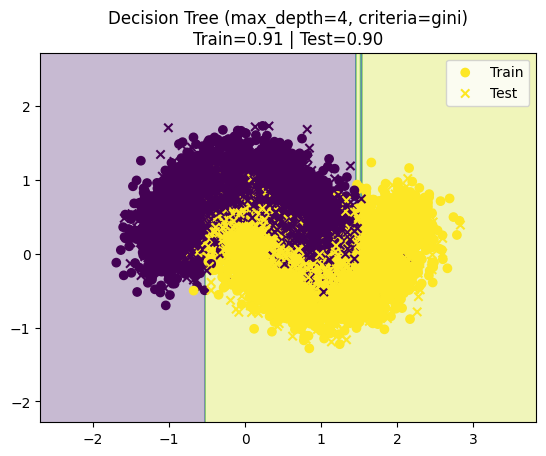

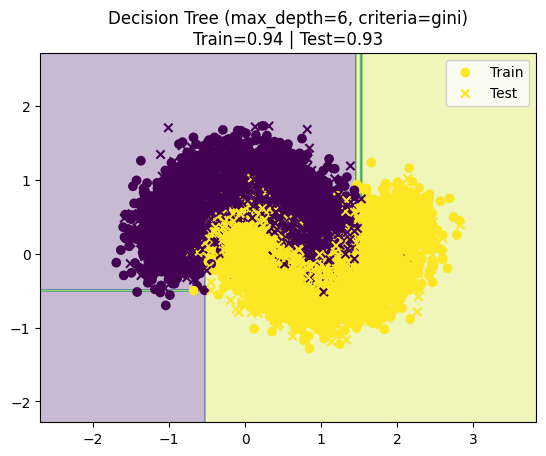

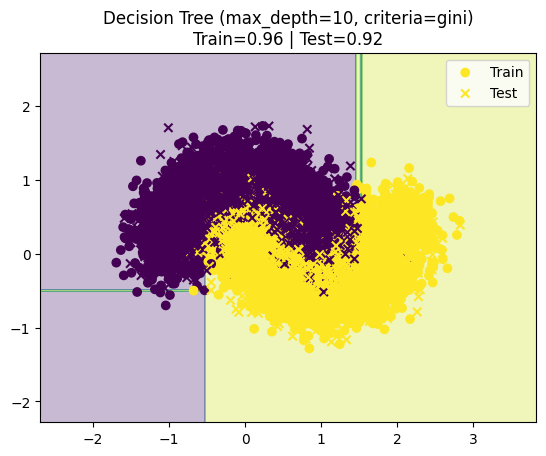

In [5]:
'''
  3. Drzewo decyzyjne
  Użyj DecisionTreeClassifier.
  Porównaj kryteria: entropia oraz Gini.
  Sprawdź wpływ różnych głębokości drzewa.
'''

# =========================================================
# DECISION TREE
# =========================================================

print("\n=== Decision Tree ===")
decTreeClassEntropy = None
decTreeClassGini = None

criteria = ["entropy","gini"]
depths = [4,6,10] #najbardziej optymalne dla depth 5 i 6, wiecej to przetrenowanie
for crit in criteria:
  for d in depths:
    model = DecisionTreeClassifier(criterion=crit, max_depth=d, random_state=42)
    model.fit(X_train, y_train)

    if crit == "entropy":
      decTreeClassEntropy = model
    else:
      decTreeClassGini = model

    plot_decision_boundary_with_metrics(
        model,
        X_train, y_train,
        X_test, y_test,
        title=f"Decision Tree (max_depth={d}, criteria={crit})"
    )


=== Random Forest Experiment ===


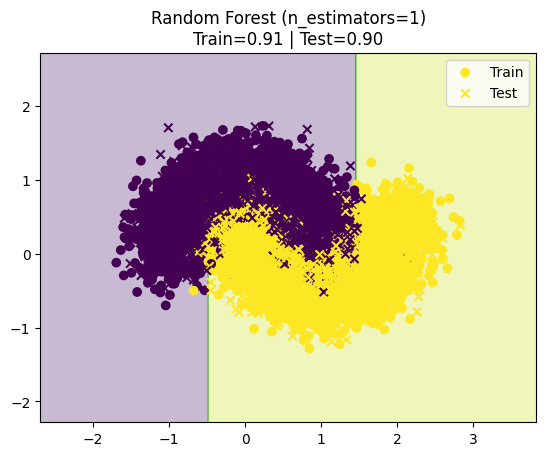

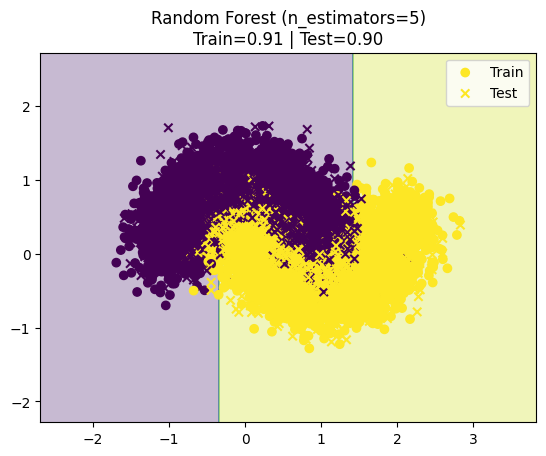

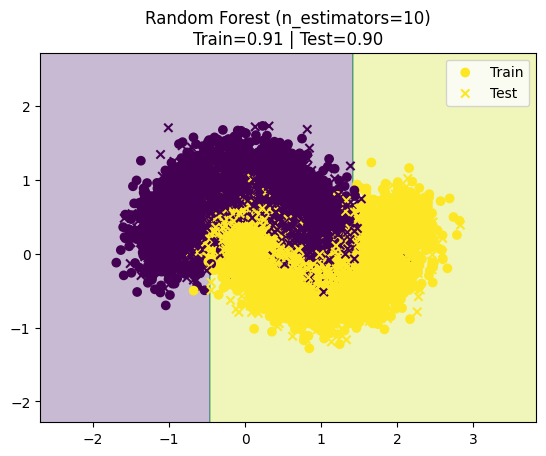

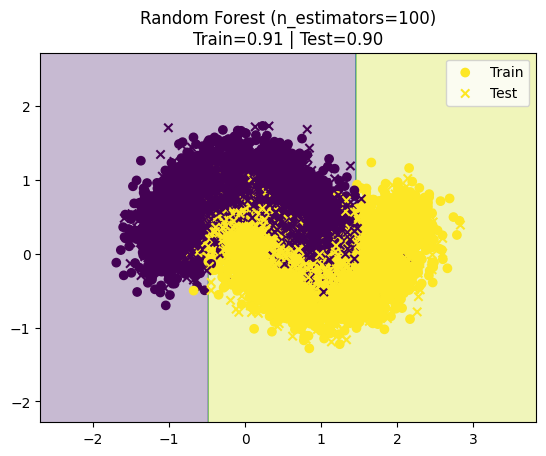

In [6]:
'''
  4. Las losowy
  Użyj RandomForestClassifier.
  Zbadaj wpływ liczby drzew na wyniki.
'''
# =========================================================
# RANDOM FOREST EXPERIMENT
# =========================================================
print("\n=== Random Forest Experiment ===")
randForestClass = None

trees = [1,5,10,100]

for n in trees:
  model = RandomForestClassifier(n_estimators=n, random_state=42, max_depth=3)
  model.fit(X_train, y_train)

  randForestClass = model

  plot_decision_boundary_with_metrics(
      model,
      X_train, y_train,
      X_test, y_test,
      title=f"Random Forest (n_estimators={n})"
  )

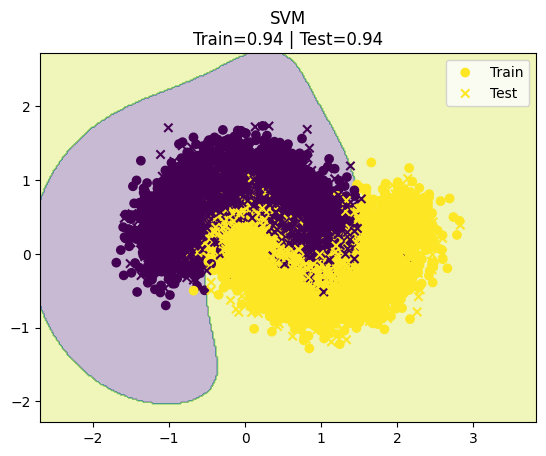

In [7]:
'''
  5. SVM
  Wytrenuj klasyfikator SVM.
'''
# =========================================================
# SVM
# =========================================================
svm = SVC(kernel="rbf", probability=True)
svm.fit(X_train, y_train)

plot_decision_boundary_with_metrics(
    svm,
    X_train, y_train,
    X_test, y_test,
    "SVM"
)

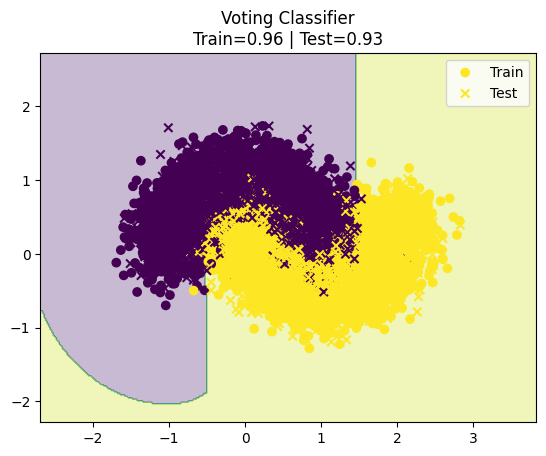

In [8]:
'''
  6. Ensemble
  Połącz SVM, LogisticRegression oraz RandomForestClassifier w VotingClassifier.
'''
# =========================================================
# ENSEMBLE
# =========================================================
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression

voting = VotingClassifier(
    estimators=[
        ("svm", SVC(probability=True)),
        ("rf", RandomForestClassifier(n_estimators=50)),
        ("lr", LogisticRegression())
    ],
    voting="hard"
)

voting.fit(X_train, y_train)

plot_decision_boundary_with_metrics(
    voting,
    X_train, y_train,
    X_test, y_test,
    title="Voting Classifier"
)

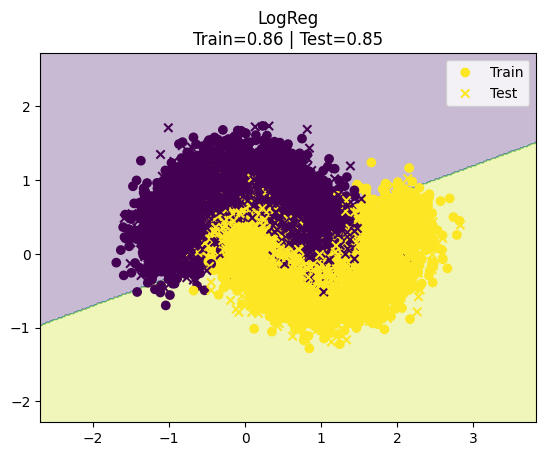

LogReg: 0.853


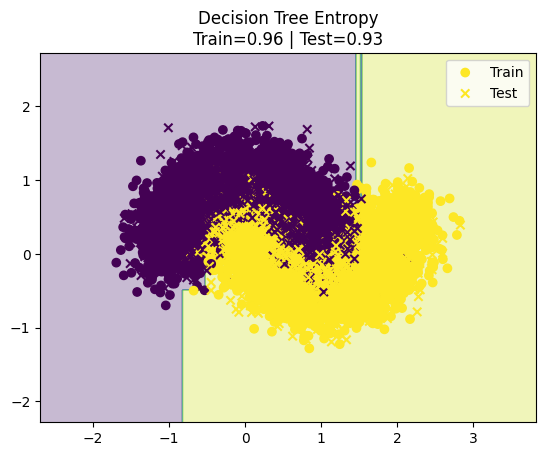

Decision Tree Entropy: 0.925


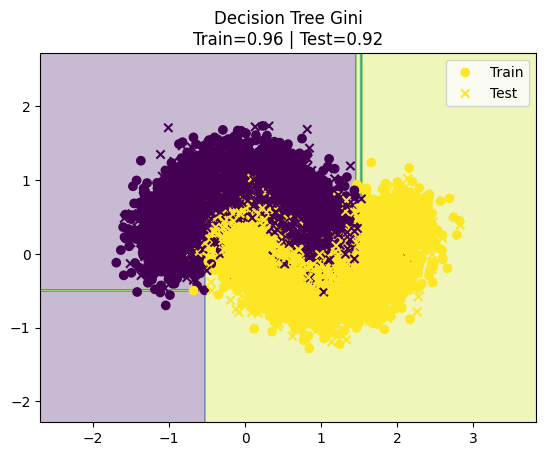

Decision Tree Gini: 0.921


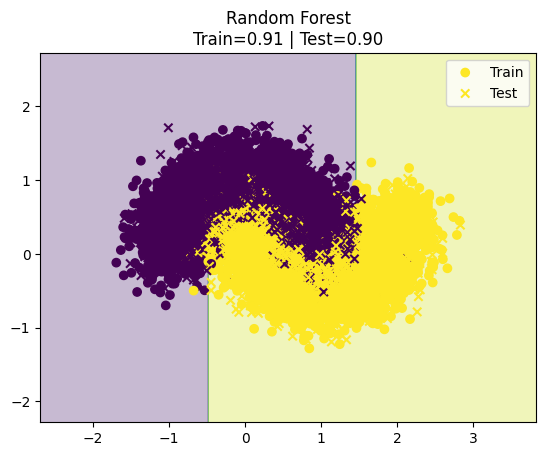

Random Forest: 0.899


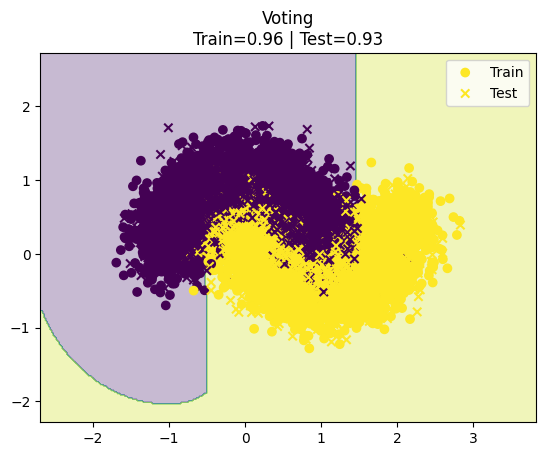

Voting: 0.931


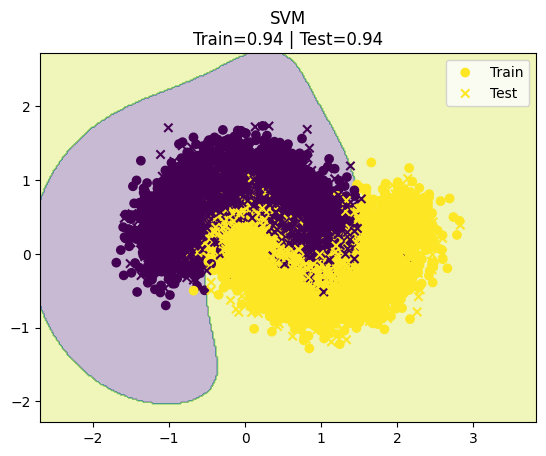

SVM: 0.935


In [9]:
from sklearn.metrics import accuracy_score

models = {
    "LogReg": logisticregression,
    "Decision Tree Entropy": decTreeClassEntropy,
    "Decision Tree Gini": decTreeClassGini,
    "Random Forest": randForestClass,
    "Voting": voting,
    "SVM": svm
}

for name, model in models.items():
    # model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)

    plot_decision_boundary_with_metrics(
    model,
    X_train, y_train,
    X_test, y_test,
    f"{name}"
    )
    print(f"{name}: {acc:.3f}")